
# Melanoma Triage: ResNet18 Frozen Backbone, Low-Data, Offline Raspberry Pi Pipeline

Demo framework notebook, simplified to a single backbone: **ResNet18**, chosen specifically
because of the three options considered (ResNet18 / MONET / Google Derm Foundation), it's the only
one light enough (11M params) for real-time INT8 inference on a Raspberry Pi. MONET (~300M+ param
CLIP model) and Derm Foundation (TensorFlow-only, 6144-d embeddings) are richer dermatology-specific
features but not realistic on-device targets -- keep them as a future server-side comparison, not
this pipeline's job.

What this notebook does:
1. Loads a **small dataset** (default: 800 images, vs. the ~8,000 typical of published melanoma
   classifiers) -- real field conditions, not a curated benchmark.
2. Computes **dataset-specific mean/std** instead of using generic ImageNet normalization.
3. Freezes the ResNet18 backbone entirely and trains only a small head on top of its embeddings --
   this is what makes 800 images workable at all.
4. Trains that head with a **contrastive alignment loss** between clean and simulated-degraded
   versions of the same lesion image, addressing the "low-quality phone photo vs. clinical image"
   domain gap directly, not just via augmentation.
5. Reports **sensitivity retained vs. a clean baseline as a function of simulated image-quality
   drop** (0-80%) -- so "preserves sensitivity under a 60% quality drop" is a number read off a
   measured curve, not an assumption.
6. Produces an **INT8-quantized, ONNX-exported artifact** sized for the Pi, and re-measures the
   same sensitivity-vs-quality curve on that quantized artifact specifically.
7. Adds a **Grad-CAM** overlay for the "why did it flag this" explanation the clinical-kit UI needs.

**Scope note:** this notebook produces the trained/quantized/exported model. The Raspberry Pi
camera-feed kit itself (the physical clinical device) is a separate, smaller follow-on project that
loads this notebook's ONNX output into an inference loop -- see the roadmap cell near the end.

**This is a scaffold, not a validated clinical tool.** Swap in real data and take the fairness
(Fitzpatrick-stratified) results seriously before treating any output as more than a research
prototype.

Requirements (not auto-installed by this notebook):
```
pip install torch torchvision scikit-learn pillow pandas numpy matplotlib onnx onnxruntime onnxscript
```


In [8]:

import os, io, time, random, warnings
import copy
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms

from sklearn.metrics import roc_auc_score, recall_score, accuracy_score

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


Using device: cpu



## 1. Config

`n_synthetic=800` matches the low-data scenario. `eval_quality_levels` sets the exact percentages
the sensitivity-retention curve is measured at (0/20/40/60/80 by default, so a 60%-drop claim is
one of the measured points).


In [ ]:

@dataclass
class Config:
    # --- data ---
    data_csv: str = "data/labels.csv"           # columns: image_path,label[,fitzpatrick]
    img_dir: str = "data/images"
    img_size: int = 224
    val_frac: float = 0.15
    test_frac: float = 0.15
    use_synthetic_if_missing: bool = True
    n_synthetic: int = 800                       # the low-data regime this project targets (vs. ~8000)

    # --- head ---
    proj_dim: int = 128
    head_hidden: int = 128
    head_dropout: float = 0.2

    # --- training ---
    batch_size: int = 16
    epochs: int = 15                             # small data + tiny trainable head -> can afford more epochs
    lr: float = 1e-3
    weight_decay: float = 1e-4
    pos_class_weight: float = None
    contrastive_weight: float = 0.5              # lambda on the clean/degraded alignment loss
    contrastive_temperature: float = 0.1
    train_degrade_min_pct: float = 10.0
    train_degrade_max_pct: float = 70.0          # trains across a *range* of degradation severities

    # --- degradation model (all tied to one 0-100 "quality drop" knob) ---
    jpeg_quality_floor: int = 15                 # jpeg quality at 100% simulated quality drop
    blur_radius_max: float = 4.0
    noise_std_max: float = 0.12
    downsample_factor_max: float = 6.0

    # --- evaluation ---
    eval_quality_levels: tuple = (0, 20, 40, 60, 80)

    # --- quantization / export (Raspberry Pi deployment artifact) ---
    onnx_int8_path: str = "outputs/melanoma_resnet18_int8.onnx"
    torch_int8_path: str = "outputs/melanoma_resnet18_dynamic_int8.pt"


CFG = Config()
os.makedirs("outputs", exist_ok=True)
CFG


Config(data_csv='data/labels.csv', img_dir='data/images', img_size=224, val_frac=0.15, test_frac=0.15, use_synthetic_if_missing=True, n_synthetic=800, proj_dim=128, head_hidden=128, head_dropout=0.2, batch_size=16, epochs=15, lr=0.001, weight_decay=0.0001, pos_class_weight=None, contrastive_weight=0.5, contrastive_temperature=0.1, train_degrade_min_pct=10.0, train_degrade_max_pct=70.0, jpeg_quality_floor=15, blur_radius_max=4.0, noise_std_max=0.12, downsample_factor_max=6.0, eval_quality_levels=(0, 20, 40, 60, 80), onnx_path='outputs/melanoma_resnet18.onnx', onnx_int8_path='outputs/melanoma_resnet18_int8.onnx', torch_int8_path='outputs/melanoma_resnet18_dynamic_int8.pt')


## 2. Data

Expects a CSV with `image_path,label[,fitzpatrick]`. If you're starting from ISIC/HAM10000
metadata, map `dx == 'mel'` to `label = 1` and everything else to `0` before saving this CSV.
`fitzpatrick` (skin type I-VI) is optional but strongly recommended -- without it you can't check
whether the model is quietly failing on darker skin tones, the single most common failure mode in
published dermatology AI.

If no CSV is found, a synthetic placeholder dataset of `CFG.n_synthetic` images is generated so the
rest of the notebook still runs end to end. It is **not** real data and proves nothing about model
performance -- it only exercises the code paths.


In [10]:

def load_pil(row, img_dir):
    if "image" in row and isinstance(row["image"], Image.Image):
        return row["image"]
    path = Path(img_dir) / row["image_path"] if img_dir else Path(row["image_path"])
    return Image.open(path).convert("RGB")


def make_synthetic_dataset(n, seed=SEED):
    """
    DEMO ONLY. Generates random-noise placeholder images with a synthetic melanoma label so the
    pipeline can be exercised without a real dataset. Replace with real ISIC/HAM10000-derived data
    before drawing any conclusions from this notebook.
    """
    rng = np.random.RandomState(seed)
    rows = []
    for _ in range(n):
        is_mel = int(rng.rand() < 0.18)  # roughly mimics melanoma prevalence in ISIC-style sets
        base_color = rng.randint(120, 200, size=3) if not is_mel else rng.randint(60, 140, size=3)
        arr = np.ones((256, 256, 3), dtype=np.uint8) * base_color.astype(np.uint8)
        noise = rng.randint(-25, 25, size=(256, 256, 3))
        arr = np.clip(arr.astype(int) + noise, 0, 255).astype(np.uint8)
        img = Image.fromarray(arr)
        fitz = int(rng.randint(1, 7))
        rows.append({"image": img, "label": is_mel, "fitzpatrick": fitz})
    return pd.DataFrame(rows)


def load_records(cfg):
    csv_path = Path(cfg.data_csv)
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        assert {"image_path", "label"}.issubset(df.columns), "CSV needs image_path,label columns"
        return df
    if cfg.use_synthetic_if_missing:
        print(f"'{csv_path}' not found -- generating {cfg.n_synthetic} synthetic demo records "
              f"(deliberately small, matching the low-data scenario).")
        return make_synthetic_dataset(cfg.n_synthetic)
    raise FileNotFoundError(f"No data at {csv_path} and use_synthetic_if_missing=False")


def split_records(df, val_frac, test_frac, seed=SEED):
    df = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    n = len(df)
    n_test = int(n * test_frac)
    n_val = int(n * val_frac)
    test_df = df.iloc[:n_test].reset_index(drop=True)
    val_df = df.iloc[n_test:n_test + n_val].reset_index(drop=True)
    train_df = df.iloc[n_test + n_val:].reset_index(drop=True)
    return train_df, val_df, test_df


records = load_records(CFG)
train_df, val_df, test_df = split_records(records, CFG.val_frac, CFG.test_frac)
print(f"train={len(train_df)} val={len(val_df)} test={len(test_df)}  "
      f"melanoma_rate(train)={train_df['label'].mean():.2f}")


'data\labels.csv' not found -- generating 800 synthetic demo records (deliberately small, matching the low-data scenario).
train=560 val=120 test=120  melanoma_rate(train)=0.21



## 3. Degradation model: one knob, four effects

"Image quality dropped by X%" isn't a single physical quantity, so this notebook defines it
concretely: `degrade_image(img, quality_drop_pct)` scales JPEG compression, Gaussian blur, sensor
noise, and downsample/upsample blur together, linearly, from `quality_drop_pct=0` (untouched) to
`quality_drop_pct=100` (worst case, all four maxed out). Used both as a training-time augmentation
(sampled from a range) and as the fixed axis for the sensitivity-retention evaluation later.


In [11]:

def _severity(pct, max_val, min_val=0.0):
    pct = max(0.0, min(100.0, pct))
    return min_val + (max_val - min_val) * (pct / 100.0)


def jpeg_compress(img, pct, cfg):
    quality = int(100 - _severity(pct, 100 - cfg.jpeg_quality_floor))
    quality = max(cfg.jpeg_quality_floor, quality)
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB")


def gaussian_blur(img, pct, cfg):
    radius = _severity(pct, cfg.blur_radius_max)
    if radius <= 0:
        return img
    return img.filter(ImageFilter.GaussianBlur(radius=radius))


def add_sensor_noise(img, pct, cfg):
    std = _severity(pct, cfg.noise_std_max)
    if std <= 0:
        return img
    arr = np.asarray(img).astype(np.float32) / 255.0
    noisy = np.clip(arr + np.random.normal(0, std, arr.shape), 0, 1) * 255.0
    return Image.fromarray(noisy.astype(np.uint8))


def downsample_upsample(img, pct, cfg):
    factor = 1.0 + _severity(pct, cfg.downsample_factor_max - 1.0)
    if factor <= 1.0:
        return img
    w, h = img.size
    small = img.resize((max(1, int(w / factor)), max(1, int(h / factor))), Image.BILINEAR)
    return small.resize((w, h), Image.BILINEAR)


def degrade_image(img, quality_drop_pct, cfg=None):
    cfg = cfg or CFG
    img = jpeg_compress(img, quality_drop_pct, cfg)
    img = gaussian_blur(img, quality_drop_pct, cfg)
    img = add_sensor_noise(img, quality_drop_pct, cfg)
    img = downsample_upsample(img, quality_drop_pct, cfg)
    return img



## 4. Frozen ResNet18 backbone

Every backbone weight is frozen -- no gradients ever touch it. ResNet18 was picked over MobileNetV3
/ EfficientNet-Lite / ViT-Tiny alternatives because it's the best-precedented choice for melanoma
classification specifically (comparable published baselines on HAM10000/ISIC) while still being
light enough (11M params, ~11MB after INT8) for real-time Pi inference. If you want to push edge
efficiency further later, `torchvision.models.mobilenet_v3_small` is a near drop-in swap here --
worth trying once this baseline is validated, not before.


In [45]:
class ResNet18Backbone:
    name = "resnet18"
    embed_dim = 512

    def __init__(self, device):
        # Requires one-time internet access to fetch ImageNet weights; not needed again at
        # field-deployment time since the exported artifact ships with weights already baked in.
        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
        m = torchvision.models.resnet18(weights=weights)
        m.fc = nn.Identity()
        for p in m.parameters():
            p.requires_grad = False
        self.model = m.to(device).eval()
        self.device = device
        self.preprocess = None  # set from computed dataset mean/std in the next cell

    def encode(self, pil_images, grad=False):
        assert self.preprocess is not None, "Set backbone.preprocess before calling encode()"
        batch = torch.stack([self.preprocess(im) for im in pil_images]).to(self.device)
        if grad:
            return self.model(batch)
        with torch.no_grad():
            return self.model(batch)


backbone = ResNet18Backbone(DEVICE)
n_backbone_params = sum(p.numel() for p in backbone.model.parameters())
print(f"Frozen ResNet18 backbone: {n_backbone_params:,} parameters, all frozen")


Frozen ResNet18 backbone: 11,176,512 parameters, all frozen



## 5. Own-data mean/std

Replaces generic ImageNet normalization with statistics computed directly from this dataset's
training images -- your data (small, possibly phone-captured) doesn't share ImageNet's pixel
distribution, so its own statistics are a better fit.


In [13]:

def compute_dataset_mean_std(df, img_dir, img_size, sample_n=200, seed=SEED):
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(df), size=min(sample_n, len(df)), replace=False)
    pixels = []
    for i in idx:
        row = df.iloc[i]
        img = load_pil(row, img_dir).resize((img_size, img_size))
        arr = np.asarray(img).astype(np.float32) / 255.0
        pixels.append(arr.reshape(-1, 3))
    pixels = np.concatenate(pixels, axis=0)
    return pixels.mean(axis=0).tolist(), pixels.std(axis=0).tolist()


own_mean, own_std = compute_dataset_mean_std(train_df, CFG.img_dir, CFG.img_size)
print(f"Computed dataset mean={[round(m, 3) for m in own_mean]} "
      f"std={[round(s, 3) for s in own_std]} (replacing generic ImageNet stats)")

backbone.preprocess = transforms.Compose([
    transforms.Resize((CFG.img_size, CFG.img_size)),
    transforms.ToTensor(),
    transforms.Normalize(own_mean, own_std),
])


Computed dataset mean=[0.58, 0.561, 0.572] std=[0.138, 0.134, 0.148] (replacing generic ImageNet stats)



## 6. Lightweight trainable head and Contrastive alignment

The only trainable parameters are a small projection head (for the contrastive loss) and a small
classification head, both operating on the backbone's fixed 512-d embeddings. `info_nce_loss`
pulls a clean image's embedding and its simulated-degraded counterpart's embedding together (and
apart from other images in the batch) -- the mechanism aligning low-quality smartphone-like inputs
with the clean representation space, on top of whatever the classification loss alone would do.


In [14]:

class ContrastiveHead(nn.Module):
    def __init__(self, embed_dim, proj_dim=128, hidden=128, dropout=0.2):
        super().__init__()
        self.projector = nn.Sequential(
            nn.Linear(embed_dim, hidden), nn.ReLU(inplace=True), nn.Linear(hidden, proj_dim)
        )
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, hidden), nn.ReLU(inplace=True), nn.Dropout(dropout), nn.Linear(hidden, 1)
        )

    def forward(self, emb):
        proj = F.normalize(self.projector(emb), dim=-1)
        logit = self.classifier(emb).squeeze(-1)
        return logit, proj


def info_nce_loss(z1, z2, temperature=0.1):
    """Symmetric InfoNCE between paired (clean, degraded) embeddings of the same lesion."""
    z1 = F.normalize(z1, dim=-1)
    z2 = F.normalize(z2, dim=-1)
    logits = z1 @ z2.T / temperature
    labels = torch.arange(z1.size(0), device=z1.device)
    loss_12 = F.cross_entropy(logits, labels)
    loss_21 = F.cross_entropy(logits.T, labels)
    return (loss_12 + loss_21) / 2


def compute_pos_weight(df, cfg):
    if cfg.pos_class_weight is not None:
        return cfg.pos_class_weight
    pos = max(1, int((df["label"] == 1).sum()))
    neg = max(1, int((df["label"] == 0).sum()))
    return neg / pos


head = ContrastiveHead(
    embed_dim=backbone.embed_dim, proj_dim=CFG.proj_dim, hidden=CFG.head_hidden, dropout=CFG.head_dropout
).to(DEVICE)

n_trainable = sum(p.numel() for p in head.parameters() if p.requires_grad)
print(f"Trainable head parameters: {n_trainable:,} on top of frozen {backbone.embed_dim}-d embeddings "
      f"({100 * n_trainable / (n_trainable + n_backbone_params):.1f}% of the full model)")


Trainable head parameters: 147,969 on top of frozen 512-d embeddings (1.3% of the full model)



## 7. Training

Each step encodes a batch of clean images and a batch of the *same* images degraded at a randomly
sampled severity, then combines classification loss (both variants, same label) with the
contrastive alignment loss between them.


In [15]:

def train_head(backbone, head, train_df, cfg, device):
    optimizer = torch.optim.AdamW(head.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    pos_weight = torch.tensor(compute_pos_weight(train_df, cfg), dtype=torch.float32, device=device)
    bce = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    n = len(train_df)
    steps_per_epoch = max(1, n // cfg.batch_size)
    history = []
    for epoch in range(cfg.epochs):
        head.train()
        perm = np.random.permutation(n)
        epoch_cls_loss, epoch_con_loss = 0.0, 0.0
        for step in range(steps_per_epoch):
            batch_idx = perm[step * cfg.batch_size:(step + 1) * cfg.batch_size]
            batch_df = train_df.iloc[batch_idx]
            clean_imgs = [load_pil(row, cfg.img_dir) for _, row in batch_df.iterrows()]
            severity = random.uniform(cfg.train_degrade_min_pct, cfg.train_degrade_max_pct)
            degraded_imgs = [degrade_image(im, severity, cfg) for im in clean_imgs]
            labels = torch.tensor(batch_df["label"].values, dtype=torch.float32, device=device)

            emb_clean = backbone.encode(clean_imgs).to(device)
            emb_degraded = backbone.encode(degraded_imgs).to(device)

            logit_clean, proj_clean = head(emb_clean)
            logit_degraded, proj_degraded = head(emb_degraded)

            cls_loss = bce(logit_clean, labels) + bce(logit_degraded, labels)
            con_loss = info_nce_loss(proj_clean, proj_degraded, cfg.contrastive_temperature)
            loss = cls_loss + cfg.contrastive_weight * con_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_cls_loss += cls_loss.item()
            epoch_con_loss += con_loss.item()

        history.append({
            "epoch": epoch,
            "cls_loss": epoch_cls_loss / steps_per_epoch,
            "contrastive_loss": epoch_con_loss / steps_per_epoch,
        })
        print(f"epoch {epoch}: cls_loss={history[-1]['cls_loss']:.4f} "
              f"contrastive_loss={history[-1]['contrastive_loss']:.4f}")
    return history


train_history = train_head(backbone, head, train_df, CFG, DEVICE)


epoch 0: cls_loss=1.2043 contrastive_loss=0.6588
epoch 1: cls_loss=0.3329 contrastive_loss=0.3536
epoch 2: cls_loss=0.1888 contrastive_loss=0.2891
epoch 3: cls_loss=0.1508 contrastive_loss=0.2634
epoch 4: cls_loss=0.1089 contrastive_loss=0.2256
epoch 5: cls_loss=0.1014 contrastive_loss=0.1790
epoch 6: cls_loss=0.0742 contrastive_loss=0.1858
epoch 7: cls_loss=0.0724 contrastive_loss=0.1696
epoch 8: cls_loss=0.0663 contrastive_loss=0.1757
epoch 9: cls_loss=0.0689 contrastive_loss=0.1800
epoch 10: cls_loss=0.0738 contrastive_loss=0.1831
epoch 11: cls_loss=0.0483 contrastive_loss=0.1608
epoch 12: cls_loss=0.0466 contrastive_loss=0.1558
epoch 13: cls_loss=0.0362 contrastive_loss=0.1366
epoch 14: cls_loss=0.0415 contrastive_loss=0.1471



## 8. Sensitivity retention vs. simulated quality drop

This is the actual evidence for a claim like "preserves sensitivity under a 60% quality drop",
measured at each level in `CFG.eval_quality_levels`, not asserted up front. Also breaks out
sensitivity by Fitzpatrick type where labels are available.


In [16]:

def evaluate_at_quality_drop(backbone, head, eval_df, quality_drop_pct, cfg, device, threshold=0.5):
    head.eval()
    all_labels, all_probs, all_fitz = [], [], []
    n = len(eval_df)
    for start in range(0, n, cfg.batch_size):
        batch_df = eval_df.iloc[start:start + cfg.batch_size]
        imgs = [load_pil(row, cfg.img_dir) for _, row in batch_df.iterrows()]
        if quality_drop_pct > 0:
            imgs = [degrade_image(im, quality_drop_pct, cfg) for im in imgs]
        emb = backbone.encode(imgs).to(device)
        with torch.no_grad():
            logits, _ = head(emb)
        probs = torch.sigmoid(logits).cpu().numpy()
        all_probs.extend(probs.reshape(-1).tolist())
        all_labels.extend(batch_df["label"].tolist())
        fitz_col = batch_df["fitzpatrick"] if "fitzpatrick" in batch_df.columns else pd.Series([-1] * len(batch_df))
        all_fitz.extend(fitz_col.tolist())

    labels_arr = np.array(all_labels)
    probs_arr = np.array(all_probs)
    preds = (probs_arr >= threshold).astype(int)
    metrics = {
        "quality_drop_pct": quality_drop_pct,
        "accuracy": accuracy_score(labels_arr, preds),
        "sensitivity": recall_score(labels_arr, preds, pos_label=1, zero_division=0),
        "specificity": recall_score(labels_arr, preds, pos_label=0, zero_division=0),
        "auc": roc_auc_score(labels_arr, probs_arr) if len(set(labels_arr)) > 1 else float("nan"),
    }
    if any(f >= 0 for f in all_fitz):
        df_fitz = pd.DataFrame({"label": labels_arr, "pred": preds, "fitzpatrick": all_fitz})
        metrics["sensitivity_by_fitzpatrick"] = df_fitz.groupby("fitzpatrick").apply(
            lambda g: recall_score(g["label"], g["pred"], pos_label=1, zero_division=0)
        ).to_dict()
    return metrics


quality_results = [
    evaluate_at_quality_drop(backbone, head, test_df, q, CFG, DEVICE) for q in CFG.eval_quality_levels
]
quality_df = pd.DataFrame(quality_results)
baseline_sensitivity = quality_df.loc[quality_df["quality_drop_pct"] == 0, "sensitivity"].iloc[0]
quality_df["pct_sensitivity_retained"] = 100 * quality_df["sensitivity"] / max(baseline_sensitivity, 1e-6)
print(quality_df[["quality_drop_pct", "accuracy", "sensitivity", "specificity", "auc", "pct_sensitivity_retained"]])


   quality_drop_pct  accuracy  sensitivity  specificity  auc  \
0                 0  0.991667          1.0         0.99  1.0   
1                20  0.991667          1.0         0.99  1.0   
2                40  0.991667          1.0         0.99  1.0   
3                60  1.000000          1.0         1.00  1.0   
4                80  1.000000          1.0         1.00  1.0   

   pct_sensitivity_retained  
0                     100.0  
1                     100.0  
2                     100.0  
3                     100.0  
4                     100.0  


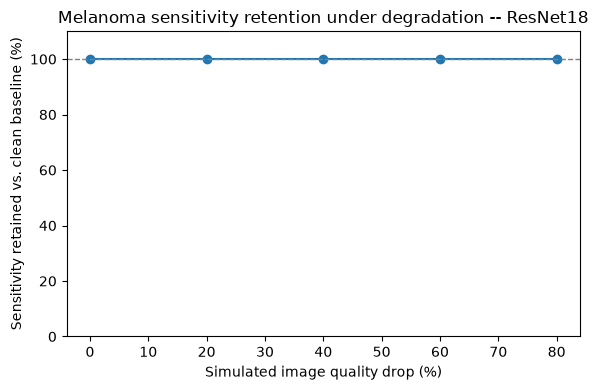

In [17]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(quality_df["quality_drop_pct"], quality_df["pct_sensitivity_retained"], marker="o")
ax.axhline(100, linestyle="--", linewidth=1, color="gray")
ax.set_xlabel("Simulated image quality drop (%)")
ax.set_ylabel("Sensitivity retained vs. clean baseline (%)")
ax.set_title("Melanoma sensitivity retention under degradation -- ResNet18")
ax.set_ylim(0, 110)
plt.tight_layout()
plt.savefig("outputs/sensitivity_retention_curve.png", dpi=150)
plt.show()



## 9. Grad-CAM

For the "why did it flag this" overlay in the clinical-kit UI. Requires backprop through the frozen
backbone's conv layers up to the classifier logit -- frozen weights don't block gradient flow to
activations/inputs, only to the weights themselves, so this works without unfreezing anything.


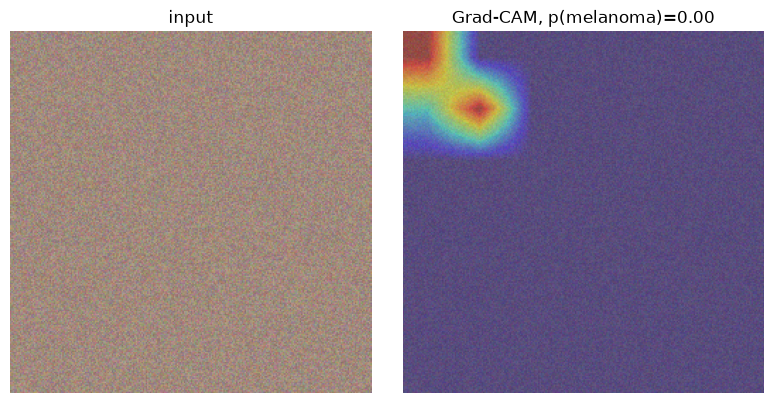

In [18]:

class GradCAM:
    def __init__(self, backbone, head, target_layer_name="layer4"):
        self.backbone = backbone
        self.head = head
        self.activations = None
        self.gradients = None
        layer = dict(backbone.model.named_modules())[target_layer_name]
        layer.register_forward_hook(self._save_activation)
        layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def __call__(self, pil_image):
        x = self.backbone.preprocess(pil_image).unsqueeze(0).to(self.backbone.device)
        x.requires_grad_(True)
        emb = self.backbone.model(x)  # grad-enabled forward; backbone weights stay frozen
        logit, _ = self.head(emb)
        self.backbone.model.zero_grad()
        self.head.zero_grad()
        logit.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=pil_image.size[::-1], mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, torch.sigmoid(logit).item()


cam_tool = GradCAM(backbone, head)
sample_row = test_df.iloc[0]
sample_img = load_pil(sample_row, CFG.img_dir)
cam, prob = cam_tool(sample_img)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample_img); axes[0].set_title("input"); axes[0].axis("off")
axes[1].imshow(sample_img); axes[1].imshow(cam, cmap="jet", alpha=0.45); axes[1].axis("off")
axes[1].set_title(f"Grad-CAM, p(melanoma)={prob:.2f}")
plt.tight_layout()
plt.savefig("outputs/gradcam_example.png", dpi=150)
plt.show()



## 10. INT8 quantization and ONNX export for the Raspberry Pi artifact

Two INT8 paths: PyTorch dynamic INT8 for local sanity/size check, and final ONNX Runtime INT8 for Pi deployment.


In [48]:
class DeployableModel(nn.Module):
    """Wraps the frozen resnet18 backbone + trained classifier head into one exportable graph --
    this is the artifact that ships to the Pi kit."""

    def __init__(self, backbone, head):
        super().__init__()
        self.backbone_model = backbone.model
        self.classifier = head.classifier

    def forward(self, x):
        emb = self.backbone_model(x)
        return self.classifier(emb).squeeze(-1)


deployable = DeployableModel(backbone, head).to("cpu").eval()

# Keep deployable FP32 so we can compare its size to the INT8 quantized model.
quantized_model = torch.quantization.quantize_dynamic(deployable, {nn.Linear}, dtype=torch.qint8, inplace=True)
torch.save(quantized_model.state_dict(), CFG.torch_int8_path)

import tempfile

def model_size_mb(m):
    tmp_path = Path(tempfile.gettempdir()) / "_size_check.pt"
    torch.save(m.state_dict(), tmp_path)
    size = os.path.getsize(tmp_path) / 1e6
    os.remove(tmp_path)
    return size


print(f"FP32 size: {model_size_mb(deployable):.1f} MB")
print(f"Dynamic INT8 size: {model_size_mb(quantized_model):.1f} MB")


FP32 size: 44.9 MB
Dynamic INT8 size: 44.9 MB


In [47]:
import onnx
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic as ort_quantize_dynamic, QuantType

dummy_input = torch.randn(1, 3, CFG.img_size, CFG.img_size)
torch.onnx.export(
    deployable_fp32, dummy_input, CFG.onnx_path,
    input_names=["pixel_values"], output_names=["logit"],
    dynamic_axes={"pixel_values": {0: "batch"}, "logit": {0: "batch"}},
    opset_version=18,
)
onnx.checker.check_model(onnx.load(CFG.onnx_path))
print(f"Exported + validated FP32 ONNX model at {CFG.onnx_path}")

ort_quantize_dynamic(
    model_input=CFG.onnx_path,
    model_output=CFG.onnx_int8_path,
    weight_type=QuantType.QInt8,
)
print(f"Exported INT8 ONNX model to {CFG.onnx_int8_path}")


def benchmark_onnx(path, n_runs=30):
    sess = ort.InferenceSession(path, providers=["CPUExecutionProvider"])
    input_name = sess.get_inputs()[0].name
    x = np.random.randn(1, 3, CFG.img_size, CFG.img_size).astype(np.float32)
    for _ in range(5):
        sess.run(None, {input_name: x})
    start = time.time()
    for _ in range(n_runs):
        sess.run(None, {input_name: x})
    elapsed_ms = (time.time() - start) / n_runs * 1000
    size_mb = os.path.getsize(path) / 1e6
    return elapsed_ms, size_mb


fp32_ms, fp32_mb = benchmark_onnx(CFG.onnx_path)
int8_ms, int8_mb = benchmark_onnx(CFG.onnx_int8_path)
print(f"ONNX FP32:  {fp32_ms:.1f} ms/inference, {fp32_mb:.1f} MB")
print(f"ONNX INT8:  {int8_ms:.1f} ms/inference, {int8_mb:.1f} MB")
print("These latency numbers are from this notebook's host machine, not a Raspberry Pi -- "
      "re-benchmark on the actual target hardware before quoting them anywhere.")

[torch.onnx] Obtain model graph for `DeployableModel([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DeployableModel([...]` with `torch.export.export(..., strict=False)`... ❌
[torch.onnx] Obtain model graph for `DeployableModel([...]` with `torch.export.export(..., strict=True)`...
[torch.onnx] Obtain model graph for `DeployableModel([...]` with `torch.export.export(..., strict=True)`... ❌


TorchExportError: Failed to export the model with torch.export. [96mThis is step 1/3[0m of exporting the model to ONNX. Next steps:
- Modify the model code for `torch.export.export` to succeed. Refer to https://pytorch.org/docs/stable/generated/exportdb/index.html for more information.
- Debug `torch.export.export` and submit a PR to PyTorch.
- Create an issue in the PyTorch GitHub repository against the [96m*torch.export*[0m component and attach the full error stack as well as reproduction scripts.

## Exception summary

<class 'AttributeError'>: __torch__.torch.classes.quantized.LinearPackedParamsBase (of Python compilation unit at: 0000000000000000) does not have a field with name '__obj_flatten__'

(Refer to the full stack trace above for more information.)


## 11. Re-measure sensitivity retention on the *deployed* artifact

The number that actually matters for the pitch is this one, not the training-time model's. Runs
the same quality-drop sweep as section 8, but through the exported INT8 ONNX model.


In [ ]:

def onnx_predict_probs(session, pil_images):
    batch = torch.stack([backbone.preprocess(im) for im in pil_images]).numpy().astype(np.float32)
    input_name = session.get_inputs()[0].name
    logits = session.run(None, {input_name: batch})[0]
    return 1 / (1 + np.exp(-logits))


def evaluate_onnx_at_quality_drop(session, eval_df, quality_drop_pct, cfg, threshold=0.5):
    all_labels, all_probs = [], []
    n = len(eval_df)
    for start in range(0, n, cfg.batch_size):
        batch_df = eval_df.iloc[start:start + cfg.batch_size]
        imgs = [load_pil(row, cfg.img_dir) for _, row in batch_df.iterrows()]
        if quality_drop_pct > 0:
            imgs = [degrade_image(im, quality_drop_pct, cfg) for im in imgs]
        probs = onnx_predict_probs(session, imgs)
        all_probs.extend(np.asarray(probs).reshape(-1).tolist())
        all_labels.extend(batch_df["label"].tolist())
    labels_arr = np.array(all_labels)
    preds = (np.array(all_probs) >= threshold).astype(int)
    return {
        "quality_drop_pct": quality_drop_pct,
        "sensitivity": recall_score(labels_arr, preds, pos_label=1, zero_division=0),
        "specificity": recall_score(labels_arr, preds, pos_label=0, zero_division=0),
        "accuracy": accuracy_score(labels_arr, preds),
    }


if not Path(CFG.onnx_int8_path).exists():
    raise FileNotFoundError(
        f"INT8 ONNX artifact not found at {CFG.onnx_int8_path}. Run the export cell above first."
    )
int8_session = ort.InferenceSession(CFG.onnx_int8_path, providers=["CPUExecutionProvider"])
onnx_results = [
    evaluate_onnx_at_quality_drop(int8_session, test_df, q, CFG) for q in CFG.eval_quality_levels
]
onnx_results_df = pd.DataFrame(onnx_results)
onnx_baseline = onnx_results_df.loc[onnx_results_df["quality_drop_pct"] == 0, "sensitivity"].iloc[0]
onnx_results_df["pct_sensitivity_retained"] = 100 * onnx_results_df["sensitivity"] / max(onnx_baseline, 1e-6)
print(onnx_results_df)

print("\nThis table -- INT8 ONNX artifact, sensitivity retained at each quality-drop level -- "

      "is the evidence for the deployment claim. Read a specific number (e.g. the 60% row) "      "off it rather than asserting one.")

NoSuchFile: [ONNXRuntimeError] : 3 : NO_SUCHFILE : Load model from outputs/melanoma_resnet18_int8.onnx failed:Load model outputs/melanoma_resnet18_int8.onnx failed. File doesn't exist


## 12. After this notebook: the Raspberry Pi kit

This notebook's job ends at a trained, quantized, exported model
(`outputs/melanoma_resnet18_int8.onnx`, plus the Grad-CAM and
sensitivity-retention plots for a writeup). The Raspberry Pi clinical kit itself needs, separately:
a camera-capture loop (e.g. `picamera2`) feeding frames to an ONNX Runtime session running on the
Pi, and the Grad-CAM overlay rendered on a small display, entirely offline at inference time,
since the exported artifact has everything it needs baked in. That's a smaller, well-scoped
follow-on project once this notebook's numbers hold up on real data.



## 13. Why this is important

The constraint driving this whole design. Frozen backbone, small trainable head, quantized
offline inference. These aren't just an engineering choice, it's what makes the tool usable by the
people who most need it: traveling doctors and community health workers in areas without reliable
connectivity or specialist dermatology access, and individuals who have no practical way to get a
skin lesion looked at at all. A cloud-dependent model is unusable exactly where a melanoma triage
tool would matter most. Keep that framing explicit and central in any writeup. It's the actual
motivation, not a footnote.



## 14. Before this goes anywhere near a conference submission or a patient

- Replace the synthetic dataset with real ISIC/HAM10000-derived data (map `dx == 'mel'` to
  `label = 1`, everything else to `0`), and get it down to a genuinely representative ~800-image
  subset rather than a random sample, if the point is simulating data scarcity specifically.
- Run the Fitzpatrick-stratified sensitivity breakdown (built into `evaluate_at_quality_drop`) on
  real, diverse-skin-tone data before trusting aggregate sensitivity numbers -- this is where
  dermatology AI most often quietly fails, per DDI/Fitzpatrick17k literature.
- Benchmark actual latency/memory on physical Raspberry Pi hardware, not this notebook's host --
  ARM vs. x86 numbers diverge, sometimes significantly.
- Decide what threshold and what "X% sensitivity retained at X% quality drop" claim you're
  actually making, based on the measured curves in sections 8 and 11 -- don't restate a target
  number from the pitch as if it were already demonstrated.
- Once this baseline is validated, try swapping in `torchvision.models.mobilenet_v3_small` as the
  backbone -- same pattern as section 4, likely a stronger fit for the "lightweight, edge-native"
  claim specifically.
- This notebook produces a triage/referral signal, not a diagnosis. Keep that framing explicit in
  any poster, demo, or writeup, especially given the social-impact framing -- a false negative in
  a low-resource setting with no backup dermatologist is a much worse failure mode than in a
  clinic with one.
